# IL-2 between helper and regulatory T cells: a feedback model in Python

In this notebook, you will turn the cartoon from the lecture into a system of **three ODEs**, solve it numerically and use it to answer the question from the lecture: *how can regulatory T cells block a weak response but not a strong one?*

> ## Programming includes looking things up
> **You are encouraged to use the internet while working through this notebook.** Looking up syntax, examples, documentation, and error messages is a normal part of programming.
>
> **The teachers are also available for questions at any time.** Please ask whenever something is unclear.

The main workflow is:

**cartoon → equations → Python function → numerical solution → plot → interpretation**


## 1. Import the packages

We use:

- **NumPy** for numerical arrays,
- **Matplotlib** for plotting,
- **SciPy** for solving ODEs.


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


### If a package is missing

If you see `ModuleNotFoundError`, install the required packages in Jupyter with:

```python
%pip install numpy matplotlib scipy
```

Then run the import cell again.



## 2. The model

Three variables (all in relative units):

- $H$: helper T cells,
- $T$: regulatory T cells (Tregs),
- $I$: the cytokine IL-2.

The processes from the cartoon:

| process | changes | depends on |
|---|---|---|
| helper T cells proliferate | $H$ ↑ | IL-2 |
| helper T cells die | $H$ ↓ | – |
| regulatory T cells proliferate | $T$ ↑ | IL-2 (higher affinity: $K_T < K_H$) |
| regulatory T cells die | $T$ ↓ | – |
| helper cells secrete IL-2 | $I$ ↑ | the antigen, which fades: $q(t) = q_0 e^{-t/\tau}$ |
| helper cells take up IL-2 | $I$ ↓ | IL-2 |
| regulatory T cells take up IL-2 | $I$ ↓ | IL-2 |
| IL-2 decays | $I$ ↓ | – |

Every row is one term: a rate × the number of cells it acts on.
Where a rate depends on IL-2, use the saturating factor from the lecture:

$\frac{I}{K + I}$

It runs from 0 (no IL-2) to 1 (saturating IL-2), and $K$ is the IL-2 level at which the rate is half-maximal.

You wrote the three equations on paper in step 2 of the exercise. Now they go into Python.


## 3. Parameters

All rates are in arbitrary units. The parameters are stored in a dictionary so that the model function receives them as one argument.


In [11]:
params = {
    "p_H": 1.2,    # helper T cells: maximal proliferation rate
    "d_H": 0.4,    #                 death rate
    "K_H": 1.0,    #                 IL-2 level for half-maximal proliferation
    "p_T": 0.7,    # regulatory T cells: maximal proliferation rate
    "d_T": 0.15,   #                     death rate
    "K_T": 0.1,    #                     half-maximal IL-2 level (K_T < K_H: higher affinity)
    "c_H": 0.3,    # IL-2 uptake per helper cell
    "c_T": 1.0,    # IL-2 uptake per regulatory T cell
    "delta": 0.3,  # IL-2 decay rate
    "tau": 4.0,    # antigen clearance time
}


### Exercise 1: translate the model into Python

Complete the function `il2_model(t, state, q0, params)`.

- `state` contains the three variables in the order `H, T, I`.
- `q0` is the strength of the antigen stimulation: the IL-2 secretion rate per helper cell at $t = 0$.
- The secretion rate fades as the antigen is cleared: $q(t) = q_0\, e^{-t/\tau}$.
- The function must return the three derivatives in the same order: `[dH_dt, dT_dt, dI_dt]`.

**Hints:**

- the saturating factor for the helpers is `I / (params["K_H"] + I)`, for the Tregs `I / (params["K_T"] + I)`;
- `np.exp(-t / params["tau"])` gives the antigen factor;
- `solve_ivp` expects the form `f(t, state, ...)`, so `t` must be the first argument even if you use it only in $q(t)$.


In [12]:
def il2_model(t, state, q0, params):
    H, T, I = state

    s_H = I / (params["K_H"] + I)          # saturating IL-2 signal seen by the helpers
    s_T = I / (params["K_T"] + I)          # ... and by the Tregs
    q = q0 * np.exp(-t / params["tau"])    # secretion per helper cell, fading with the antigen

    dH_dt = params["p_H"] * s_H * H - params["d_H"] * H
    dT_dt = params["p_T"] * s_T * T - params["d_T"] * T
    dI_dt = q * H - params["c_H"] * s_H * H - params["c_T"] * s_T * T - params["delta"] * I

    return [dH_dt, dT_dt, dI_dt]


### Check your function

Before solving anything, call the function at two test points. The expected values are given, so sign errors or a missing saturation show up now rather than in a confusing plot.

- With no IL-2 yet ($t = 0$, $I = 0$) both cell types only die and the helpers only secrete.
- With $I = 1$ the saturating terms are at work.


In [13]:
print(np.round(il2_model(0, [1.0, 0.2, 0.0], 3.0, params), 3), "  expected [-0.4, -0.03, 3.0]")
print(np.round(il2_model(0, [1.0, 0.2, 1.0], 3.0, params), 3), "  expected [0.2, 0.097, 2.368]")


[-0.4  -0.03  3.  ]   expected [-0.4, -0.03, 3.0]
[0.2   0.097 2.368]   expected [0.2, 0.097, 2.368]


## 4. Solve the model numerically

To solve the model, we need:

1. the ODE function,
2. a time interval,
3. the initial values of $H$, $T$ and $I$,
4. the parameter values,
5. time points at which we want the solution.

We start with **strong stimulation with Tregs**:

- $q_0 = 4$,
- $H(0) = 1$, $T(0) = 0.2$, $I(0) = 0$,
- simulation from $t = 0$ to $t = 40$.

Because the helper cells expand by orders of magnitude, use `method="LSODA"` in `solve_ivp`: it handles the fast and slow phases of the response.

### Exercise 2: simulate strong stimulation with Tregs

Call `solve_ivp` with `il2_model`, `t_span=(0, 40)`, `y0=[1, 0.2, 0]`, `args=(4.0, params)`, `t_eval=times` and `method="LSODA"`.

Then print the maximum number of helper cells, `solution.y[0].max()`. By how much do they expand?


In [15]:
times = np.linspace(0, 40, 400)

solution = solve_ivp(
    il2_model,
    t_span=(0, 40),
    y0=[1, 0.2, 0],
    args=(4.0, params),
    t_eval=times,
    method="LSODA"
)

print("maximum helper T cells:", round(solution.y[0].max()))


maximum helper T cells: 2712


### Exercise 3: plot the three variables

Plot $H(t)$, $T(t)$ and $I(t)$ in three panels next to each other.

- `solution.t` on the x-axis, `solution.y[0]`, `solution.y[1]`, `solution.y[2]` on the y-axes.
- Cell numbers span several orders of magnitude: use a **logarithmic y-axis** for $H$ and $T$ (`ax.set_yscale("log")`), a linear one for IL-2.
- Add axis labels and titles.

**Hint:** `fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))` gives three panels; `ax[0]`, `ax[1]`, `ax[2]` are the axes.


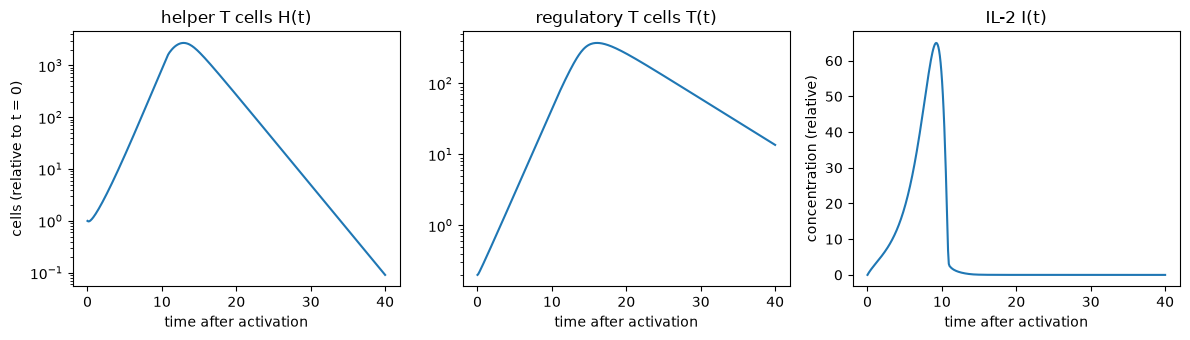

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))

ax[0].plot(solution.t, solution.y[0])
ax[0].set_yscale("log")
ax[0].set_title("helper T cells H(t)")

ax[1].plot(solution.t, solution.y[1])
ax[1].set_yscale("log")
ax[1].set_title("regulatory T cells T(t)")

ax[2].plot(solution.t, solution.y[2])
ax[2].set_title("IL-2 I(t)")

for a in ax:
    a.set_xlabel("time after activation")
ax[0].set_ylabel("cells (relative to t = 0)")
ax[2].set_ylabel("concentration (relative)")

plt.tight_layout()
plt.show()


## 5. Compare scenarios

The question from the lecture needs four runs: **weak** and **strong** stimulation, each **with** and **without** Tregs.

Without Tregs means $T(0) = 0$: the Treg equation then stays at zero by itself, no change to the model is needed.

### Exercise 4: four scenarios in one figure

Simulate the four scenarios below and plot $H(t)$ for all of them in one figure (log y-axis, legend):

| scenario | `q0` | `T0` |
|---|---|---|
| weak stimulation, with Tregs | 1.5 | 0.2 |
| weak stimulation, no Tregs | 1.5 | 0 |
| strong stimulation, with Tregs | 4.0 | 0.2 |
| strong stimulation, no Tregs | 4.0 | 0 |

**Hint:** put the scenarios in a list of tuples `(label, q0, T0)` and use a `for` loop, as in the ODE notebook. Inside the loop, `y0=[1, T0, 0]`.


weak stimulation, with Tregs     maximum helper T cells:      1.8
weak stimulation, no Tregs       maximum helper T cells:     34.7
strong stimulation, with Tregs   maximum helper T cells:   2712.0
strong stimulation, no Tregs     maximum helper T cells:   6224.5


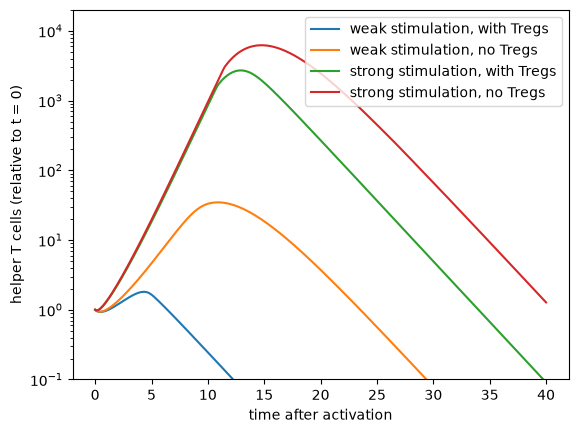

In [17]:
scenarios = [
    ("weak stimulation, with Tregs",   1.5, 0.2),
    ("weak stimulation, no Tregs",     1.5, 0.0),
    ("strong stimulation, with Tregs", 4.0, 0.2),
    ("strong stimulation, no Tregs",   4.0, 0.0),
]

for label, q0, T0 in scenarios:
    sol = solve_ivp(
        il2_model,
        t_span=(0, 40),
        y0=[1, T0, 0],
        args=(q0, params),
        t_eval=times,
        method="LSODA"
    )
    plt.plot(sol.t, sol.y[0], label=label)
    print(f"{label:32s} maximum helper T cells: {sol.y[0].max():8.1f}")

plt.yscale("log")
plt.ylim(0.1, 2e4)
plt.xlabel("time after activation")
plt.ylabel("helper T cells (relative to t = 0)")
plt.legend()
plt.show()


### Exercise 5: interpret the result

Answer in the cell below (double-click to edit, Shift + Enter to render):

1. What do the Tregs do to the **weak** response? And to the **strong** one?
2. Which term in the equations makes the difference between the two cases?


*Answer:*

1. **Weak stimulation:** without Tregs the helpers expand about 35-fold; with Tregs they do not expand at all (×1.8, then they decline). **Strong stimulation:** the helpers expand in both cases (×6200 without Tregs, ×2700 with) — the Tregs trim the response and end it earlier, but they cannot hold it.
2. The Treg uptake term $c_T\, T\, \frac{I}{K_T + I}$ together with the Treg proliferation term. Because $K_T < K_H$, the Tregs take the IL-2 away while it is still too scarce for the helpers; and because the Tregs grow on IL-2, the sink grows with the response. At strong stimulation the uptake saturates ($I \gg K_T$) while secretion $q(t) H$ keeps growing with the helpers, so the sink falls behind.


## 6. If you are done: where is the threshold?

### Exercise 6: find the stimulation strength at which the helpers start to expand

Loop over `q0` values from 0.5 to 4 (for example `np.linspace(0.5, 4, 15)`), simulate with Tregs (`T0 = 0.2`) and without (`T0 = 0`), and record the maximum of $H$ for each run. Plot the maximum against `q0` on a log y-axis.

- At which `q0` does the peak rise above 1 (no expansion) in each case?
- Double `T0` to 0.4. What happens to the threshold?


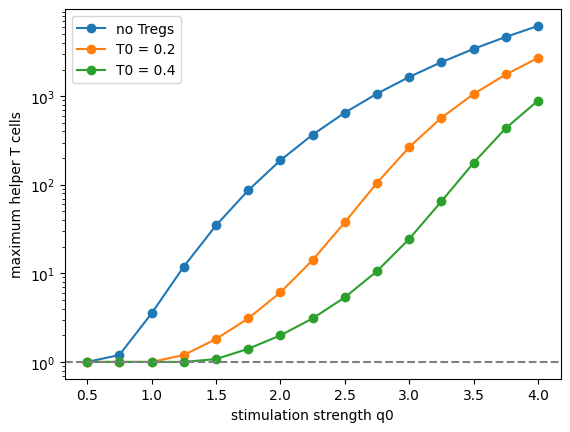

In [8]:
q0_values = np.linspace(0.5, 4, 15)

for T0, label in [(0.0, "no Tregs"), (0.2, "T0 = 0.2"), (0.4, "T0 = 0.4")]:
    peaks = []
    for q0 in q0_values:
        sol = solve_ivp(il2_model, t_span=(0, 40), y0=[1, T0, 0], args=(q0, params), t_eval=times, method="LSODA")
        peaks.append(sol.y[0].max())
    plt.plot(q0_values, peaks, "o-", label=label)

plt.axhline(1, color="grey", linestyle="--")
plt.yscale("log")
plt.xlabel("stimulation strength q0")
plt.ylabel("maximum helper T cells")
plt.legend()
plt.show()


## Summary: what you learned

In this notebook, you learned how to:

- turn a cartoon with eight processes into three coupled ODEs,
- write a saturating (Hill-type) dependence on a signal,
- pass several parameters to `solve_ivp` with a dictionary,
- check an ODE function at test points before solving,
- use a log axis for quantities that span orders of magnitude,
- compare scenarios in a loop and in one figure,
- read a mechanism off the simulations: a positive and a negative feedback loop competing for the same cytokine.

The main workflow is:

**define the model → choose initial values and parameters → solve → visualize → interpret**
